In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_csv(r'D:\AQI Project\final_completed_data.csv')
data.tail()

,Unnamed: 0,Station,Date,latitude,longitude,PM2_5_ugm3,PM10_ugm3,TSP_ugm3,PM1_generic_ugm3,era5_t2m_c,...,era5_dewpoint_c,era5_wind_u_ms,era5_wind_v_ms,era5_surface_pressure_hpa,era5_precip_mm,era5_solar_rad_mj_m2,day_index,day_of_year,sin_day,cos_day
25562,25562,TU / Kirtipur,2025-12-27,27.6789,85.2911,23.760306,41.952459,84.764032,71.206475,10.135457,...,7.164640,0.469504,0.494139,839.087743,0.045166,13.231976,3648,361,-0.073045,0.997329
25563,25563,TU / Kirtipur,2025-12-28,27.6789,85.2911,23.760306,41.790693,84.796623,71.206475,10.096075,...,7.627770,0.370026,0.580058,839.067697,0.041950,11.909588,3649,362,-0.055879,0.998438
25564,25564,TU / Kirtipur,2025-12-29,27.6789,85.2911,23.760306,41.831390,84.779926,71.206475,9.204797,...,6.421451,0.433288,0.531261,838.141042,0.015873,12.110436,3650,363,-0.038696,0.999251
25565,25565,TU / Kirtipur,2025-12-30,27.6789,85.2911,23.760306,41.858514,84.781466,71.206475,8.513927,...,6.221277,0.285515,0.589950,836.512629,0.010258,12.319148,3651,364,-0.021501,0.999769
25566,25566,TU / Kirtipur,2025-12-31,27.6789,85.2911,23.760306,41.854631,84.779964,71.206475,9.392521,...,5.853055,0.172586,0.487172,836.574333,0.001290,14.625820,3652,365,-0.004301,0.999991


In [3]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 25567 entries, 0 to 25566
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Unnamed: 0                 25567 non-null  int64  
 1   Station                    25567 non-null  str    
 2   Date                       25567 non-null  str    
 3   latitude                   25567 non-null  float64
 4   longitude                  25567 non-null  float64
 5   PM2_5_ugm3                 25567 non-null  float64
 6   PM10_ugm3                  25567 non-null  float64
 7   TSP_ugm3                   25567 non-null  float64
 8   PM1_generic_ugm3           25567 non-null  float64
 9   era5_t2m_c                 25567 non-null  float64
 10  era5_tmax_c                25567 non-null  float64
 11  era5_tmin_c                25567 non-null  float64
 12  era5_dewpoint_c            25567 non-null  float64
 13  era5_wind_u_ms             25567 non-null  float64
 14  e

In [4]:
print(data.columns.tolist())

['Unnamed: 0', 'Station', 'Date', 'latitude', 'longitude', 'PM2_5_ugm3', 'PM10_ugm3', 'TSP_ugm3', 'PM1_generic_ugm3', 'era5_t2m_c', 'era5_tmax_c', 'era5_tmin_c', 'era5_dewpoint_c', 'era5_wind_u_ms', 'era5_wind_v_ms', 'era5_surface_pressure_hpa', 'era5_precip_mm', 'era5_solar_rad_mj_m2', 'day_index', 'day_of_year', 'sin_day', 'cos_day']


In [5]:
print(data.isna().mean())

Unnamed: 0                   0.0
Station                      0.0
Date                         0.0
latitude                     0.0
longitude                    0.0
PM2_5_ugm3                   0.0
PM10_ugm3                    0.0
TSP_ugm3                     0.0
PM1_generic_ugm3             0.0
era5_t2m_c                   0.0
era5_tmax_c                  0.0
era5_tmin_c                  0.0
era5_dewpoint_c              0.0
era5_wind_u_ms               0.0
era5_wind_v_ms               0.0
era5_surface_pressure_hpa    0.0
era5_precip_mm               0.0
era5_solar_rad_mj_m2         0.0
day_index                    0.0
day_of_year                  0.0
sin_day                      0.0
cos_day                      0.0
dtype: float64


In [6]:
target_columns = ['PM2_5_ugm3', 'PM10_ugm3', 'TSP_ugm3', 'PM1_generic_ugm3']

sequence_length = 30 

In [7]:
from torch.utils.data import TensorDataset , DataLoader
from sklearn.preprocessing import StandardScaler

In [8]:
data['Date'] = pd.to_datetime(data['Date'])

In [9]:
data= data.sort_values(['Station' , 'Date']).reset_index(drop = True)

data.drop(columns = 'Unnamed: 0' , inplace = True ,errors= 'ignore')

Few cells below are only for data information. Different ways data and its properties can be displayed

In [10]:
data.head()

,Station,Date,latitude,longitude,PM2_5_ugm3,PM10_ugm3,TSP_ugm3,PM1_generic_ugm3,era5_t2m_c,era5_tmax_c,...,era5_dewpoint_c,era5_wind_u_ms,era5_wind_v_ms,era5_surface_pressure_hpa,era5_precip_mm,era5_solar_rad_mj_m2,day_index,day_of_year,sin_day,cos_day
0,Bhaisipati,2016-01-01,27.6531,85.3023,61.876329,60.561532,124.740568,41.702402,10.453877,14.902155,...,5.648932,0.305060,0.286913,844.680195,0.030476,14.330336,0,1,0.017202,0.999852
1,Bhaisipati,2016-01-02,27.6531,85.3023,65.919570,70.489678,287.693493,40.511853,10.373492,15.119623,...,6.078643,0.414108,0.481743,843.029232,0.328749,13.767144,1,2,0.034398,0.999408
2,Bhaisipati,2016-01-03,27.6531,85.3023,50.025353,51.332659,65.331941,41.231615,9.558183,13.219385,...,4.292931,0.217866,0.148770,841.957345,0.077382,12.952460,2,3,0.051584,0.998669
3,Bhaisipati,2016-01-04,27.6531,85.3023,41.687705,45.237691,91.972702,38.204210,9.852491,14.502313,...,3.607865,0.239501,0.159103,842.964928,0.003636,14.524208,3,4,0.068755,0.997634
4,Bhaisipati,2016-01-05,27.6531,85.3023,67.007479,59.866934,149.102133,39.654774,10.233762,14.897424,...,5.302685,0.513052,0.494841,841.336104,0.103569,14.141148,4,5,0.085906,0.996303


In [11]:
import torch
print("CUDA available : " , torch.cuda.is_available())

CUDA available :  False


In [12]:
data.describe()

,Date,latitude,longitude,PM2_5_ugm3,PM10_ugm3,TSP_ugm3,PM1_generic_ugm3,era5_t2m_c,era5_tmax_c,era5_tmin_c,era5_dewpoint_c,era5_wind_u_ms,era5_wind_v_ms,era5_surface_pressure_hpa,era5_precip_mm,era5_solar_rad_mj_m2,day_index,day_of_year,sin_day,cos_day
count,25567,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,25567.000000,2.556700e+04,25567.000000,25567.000000,25567.000000,25567.000000
mean,2020-12-30 17:08:37.182305,27.677071,85.362072,41.684241,64.962811,156.794710,47.612215,94.402496,98.561125,90.710360,90.111188,0.217864,0.206849,24550.661230,5.917435,4.529779e+06,1825.714319,183.121837,0.000007,-0.000020
min,2016-01-01 00:00:00,27.618330,85.291100,0.100000,0.100000,0.100000,0.100000,4.749824,7.961664,-0.501044,-3.781292,-1.371661,-1.131910,825.767220,-0.000028,1.157940e+00,0.000000,1.000000,-0.999999,-0.999979
25%,2018-07-02 00:00:00,27.653100,85.302300,23.760306,34.851801,50.892448,32.112242,14.615888,19.207147,10.120432,8.347965,0.021765,0.017869,836.479797,0.004934,1.408802e+01,913.000000,92.000000,-0.703677,-0.707487
50%,2020-12-31 00:00:00,27.678900,85.318841,39.374058,56.264005,124.513844,51.314204,19.888322,23.327234,17.269327,17.632495,0.242055,0.236253,839.749544,0.271559,1.815643e+01,1826.000000,183.000000,-0.004301,0.001075
75%,2023-07-02 00:00:00,27.700000,85.417500,57.258997,87.656961,194.792918,71.206475,283.688622,288.508499,278.967461,277.866411,0.434340,0.429248,83409.369141,6.004633,1.020314e+07,2739.000000,274.000000,0.706727,0.702913
max,2025-12-31 00:00:00,27.732800,85.551940,397.610000,736.600000,3197.220000,372.230000,296.580029,302.527267,293.458282,294.632830,1.336867,0.974520,84720.647624,328.477919,2.932366e+07,3652.000000,366.000000,0.999986,0.999991
std,NaN,0.033169,0.086760,24.318307,47.484201,191.023581,22.731228,123.489360,123.506976,123.440858,123.529110,0.297789,0.299594,37490.446259,15.079917,7.649915e+06,1054.385948,105.438905,0.707128,0.707114


In [13]:
print('Number of stations : ' , data['Station'].nunique())

print(data.groupby('Station')['Date'].agg(['min' , 'max' , 'count']))

Number of stations :  7
                     min        max  count
Station                                   
Bhaisipati    2016-01-01 2025-12-30   3652
Bhaktapur     2016-01-01 2025-12-30   3652
Dhulikhel     2016-01-01 2025-12-31   3653
Pulchowk      2016-01-01 2025-12-31   3653
Ratnapark     2016-01-01 2025-12-30   3652
Shankhapark   2016-01-01 2025-12-30   3652
TU / Kirtipur 2016-01-01 2025-12-31   3653


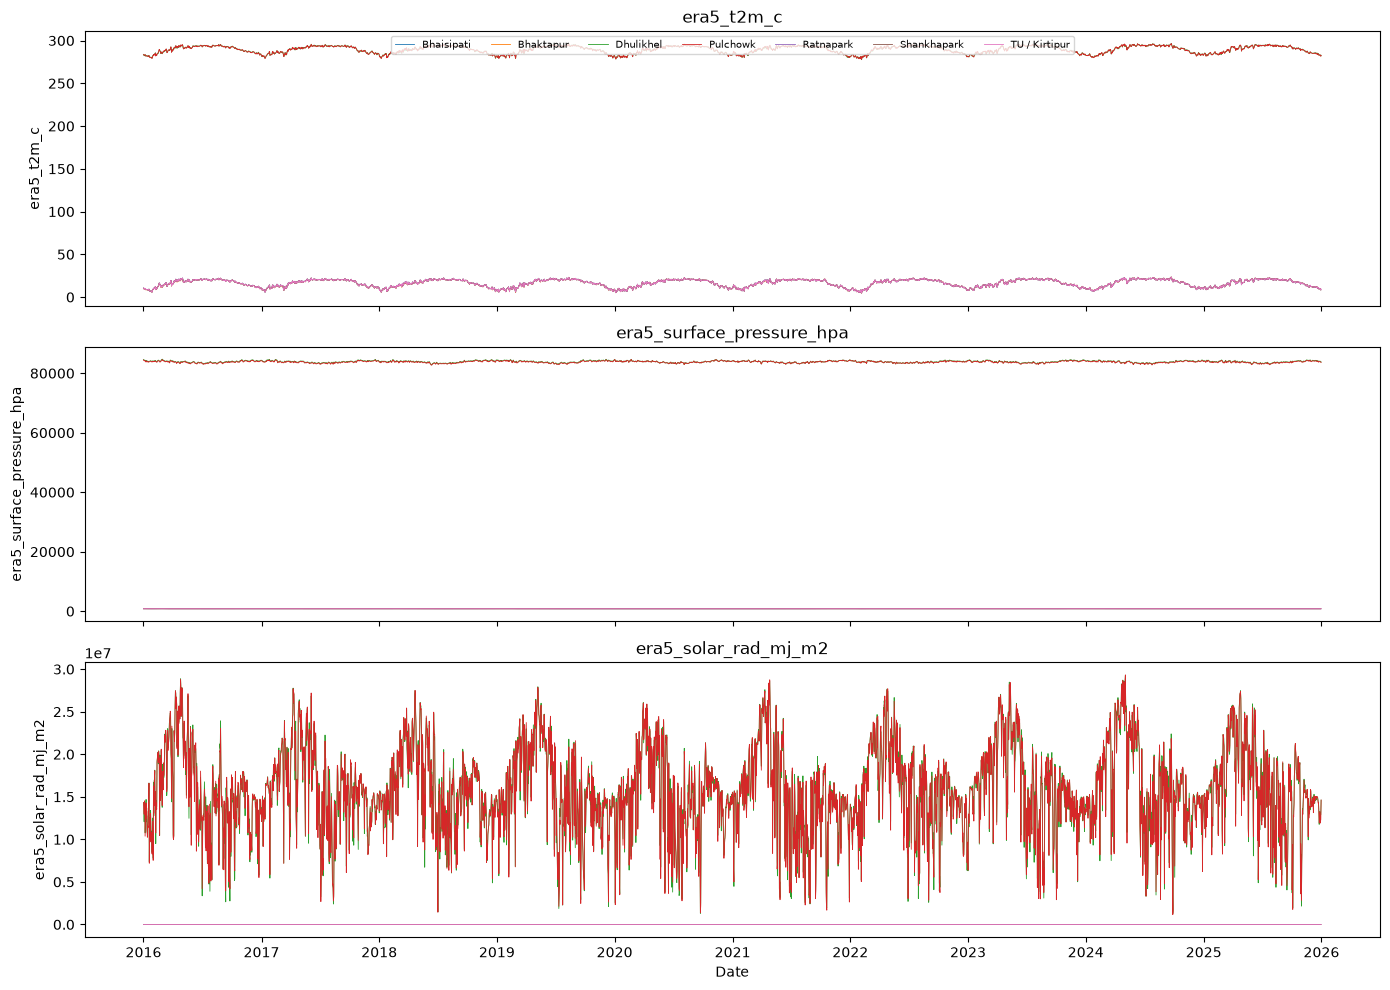

In [14]:
import matplotlib.pyplot as plt

data = pd.read_csv(r'D:\AQI Project\final_completed_data.csv' , parse_dates= ['Date'])


fig , axes = plt.subplots(3,1, figsize = (14,10) , sharex = True)

for ax , col in zip(axes , ["era5_t2m_c", "era5_surface_pressure_hpa", "era5_solar_rad_mj_m2"]):
    for station , df in data.groupby('Station'):
        ax.plot(df['Date'] , df[col] , lw = 0.6 , label = station)

    ax.set_ylabel(col)
    ax.set_title(col)


axes[-1].set_xlabel('Date')
axes[0].legend(fontsize = 7 , ncol = 7 , loc = 'upper center')

plt.tight_layout()
plt.show()

In [ ]:
unit_check = data.groupby('Station')[["era5_t2m_c", "era5_surface_pressure_hpa", "era5_solar_rad_mj_m2"]].mean()


print(unit_check)

               era5_t2m_c  era5_surface_pressure_hpa  era5_solar_rad_mj_m2
Station                                                                   
Bhaisipati      16.348538                 837.671995          1.584033e+01
Bhaktapur       16.314354                 838.072873          1.582665e+01
Dhulikhel      289.528761               83872.733252          1.586342e+07
Pulchowk       289.496634               83767.169423          1.584000e+07
Ratnapark       16.348538                 837.671995          1.584033e+01
Shankhapark     16.348538                 837.671995          1.584033e+01
TU / Kirtipur   16.346634                 837.671694          1.584000e+01


In [19]:
num= ['Bhaisipati' , 'Pulchowk']
print(data['Station'].isin(num))

0         True
1         True
2         True
3         True
4         True
         ...  
25562    False
25563    False
25564    False
25565    False
25566    False
Name: Station, Length: 25567, dtype: bool


In [20]:
err_stations = ['Dhulikhel' , 'Pulchowk']
mask = data['Station'].isin(err_stations)

data.loc[mask, "era5_t2m_c"] -= 273.15
data.loc[mask , 'era5_tmax_c'] -=273.15
data.loc[mask , 'era5_tmin_c'] -=273.15
data.loc[mask , 'era5_dewpoint_c'] -=273.15

data.loc[mask , 'era5_surface_pressure_hpa'] /= 180


data.loc[mask , 'era5_solar_rad_mj_m2'] /= 1000000


In [21]:
unit_check = data.groupby('Station')[["era5_t2m_c", "era5_surface_pressure_hpa", "era5_solar_rad_mj_m2"]].mean()


print(unit_check)

               era5_t2m_c  era5_surface_pressure_hpa  era5_solar_rad_mj_m2
Station                                                                   
Bhaisipati      16.348538                 837.671995             15.840333
Bhaktapur       16.314354                 838.072873             15.826650
Dhulikhel       16.378761                 465.959629             15.863415
Pulchowk        16.346634                 465.373163             15.840000
Ratnapark       16.348538                 837.671995             15.840333
Shankhapark     16.348538                 837.671995             15.840333
TU / Kirtipur   16.346634                 837.671694             15.840000
